In [1]:
# %pip install pandas
# %pip install numpy
# %pip install scipy
# %pip install matplotlib

import pandas as pd
import numpy as np
import os
from scipy.optimize import minimize
from scipy.stats import lognorm
import matplotlib.pyplot as plt

In [2]:
data = pd.read_csv("7267433/bt_symmetric.csv")

In [3]:
# Convert timestamps from seconds to study days (starting at day 0).
data["study_day"] = data["# timestamp"] // 86400

# Keep records with a valid first participant.
data = data[data["user_a"] >= 0]

# Keep records with a valid second participant.
data = data[data["user_b"] >= 0]

In [4]:
data.head()

,# timestamp,user_a,user_b,rssi,study_day
15,0,21,20,-73,0
34,0,47,19,-86,0
36,0,49,48,-62,0
51,0,69,44,-87,0
66,0,90,64,-96,0


In [ ]:
# Aggregate all scans in the second week (measured relative to study days)
week2 = data[data["study_day"].between(7, 13)]

edges = pd.DataFrame({
    "user_a": week2[["user_a", "user_b"]].min(axis=1),
    "user_b": week2[["user_a", "user_b"]].max(axis=1),
})

edges = edges[edges["user_a"] != edges["user_b"]].drop_duplicates().reset_index(drop=True)

In [6]:
# Count the distinct days on which each pair was observed.
daily_pairs = week2[["study_day", "user_a", "user_b"]].drop_duplicates()

edges = (
    daily_pairs.groupby(["user_a", "user_b"])
    .size()
    .reset_index(name="day_count")
)

edges = edges[
    (edges["day_count"] >= 2)
    & (edges["user_a"] != edges["user_b"])
].reset_index(drop=True)

In [9]:
# Count each node's distinct neighbors in the filtered edge list.
degrees = pd.concat(
      [edges["user_a"], edges["user_b"]]
  ).value_counts().to_numpy()

# Minimize negative log-likelihood
def negative_log_likelihood(params):
    mu, log_sigma = params
    return -lognorm.logpdf(degrees, s=np.exp(log_sigma), scale=np.exp(mu)).sum()

result = minimize(
    negative_log_likelihood,
    x0=[np.log(degrees).mean(), 0.0],
    method="Nelder-Mead",
)

mu, sigma = result.x[0], np.exp(result.x[1])
print(f"mu = {mu:.4f}, sigma = {sigma:.4f}")

mu = 3.1815, sigma = 0.9338


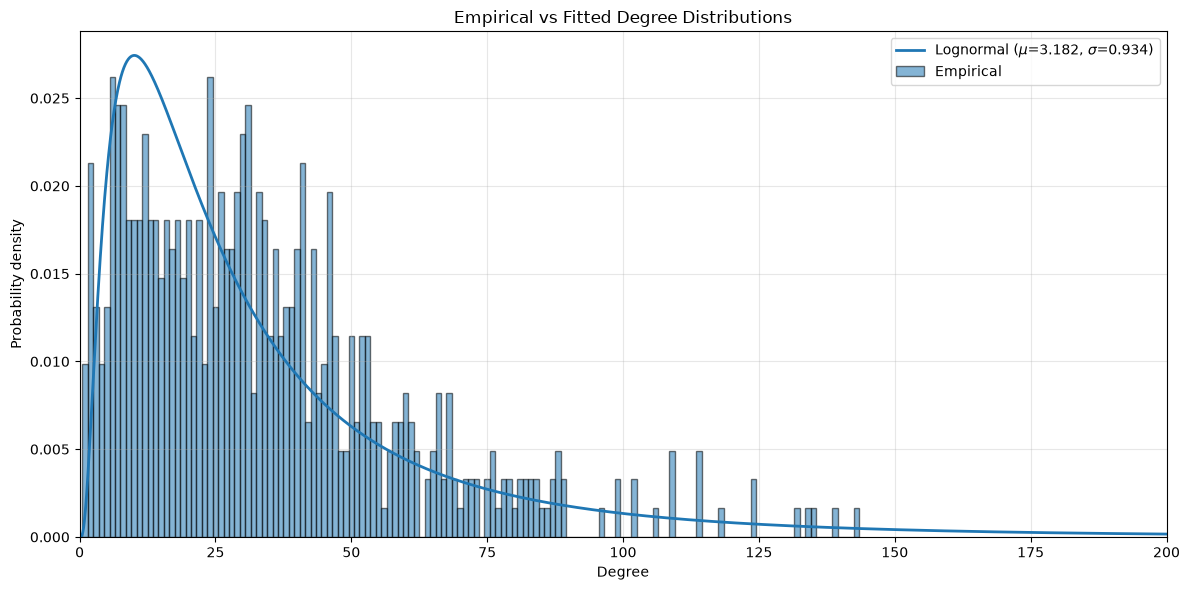

In [10]:
# Plot empirical vs. actual degree distribution
bins = np.arange(0.5, degrees.max() + 1.5, 1)
x_max = max(200, degrees.max() + 1)
x = np.linspace(0.01, x_max, 3000)

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    x,
    lognorm.pdf(x, s=sigma, scale=np.exp(mu)),
    color="tab:blue",
    linewidth=2,
    label=fr"Lognormal ($\mu$={mu:.3f}, $\sigma$={sigma:.3f})",
)

ax.hist(
    degrees,
    bins=bins,
    density=True,
    color="tab:blue",
    edgecolor="black",
    alpha=0.55,
    label="Empirical",
)

ax.set(
    title="Empirical vs Fitted Degree Distributions",
    xlabel="Degree",
    ylabel="Probability density",
    xlim=(0, x_max),
)
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()

fig.savefig("cns_degree_distribution.pdf", bbox_inches="tight")
fig.savefig("cns_degree_distribution.png", dpi=300, bbox_inches="tight")
plt.show()